<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Datos Masivos II · PRÁCTICA 4</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Recomendador híbrido de ligandos para proteínas</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

**Qué hace.** Dada una proteína, ordena moléculas por la potencia con que se le unirían y devuelve las mejores.

**De dónde sale.** Las tres tablas de `02_limpieza.ipynb`: 1.25 millones de mediciones de afinidad entre 3,444 proteínas humanas y 832 mil moléculas.

**Cómo está armado.** Cuatro modelos de referencia y un híbrido, comparados con métricas de ranking, y el recomendador funcionando al final sobre proteínas reales.

**Tiempo.** ~7 min con la caché de huellas construida (la primera vez, ~13 min).

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. El problema</span></div>

### Vocabulario

| Término | Qué es | Rol |
|---|---|---|
| **proteína** | la molécula biológica a la que se apunta (`target_id`, *accession* de UniProt) | **usuario** |
| **ligando** | la molécula pequeña que se adhiere a ella (`lig_id`) | **ítem** |
| **IC50** | concentración de ligando necesaria para inhibir a la mitad. Menos = se une más fuerte | — |
| **pIC50** | `9 − log₁₀(IC50 nM)`. Logarítmica y con el signo volteado: **más alto = más potente** | **calificación** |
| **activo** | `pIC50 ≥ 6` (1 µM), el corte habitual en química medicinal | calificación binaria |

La palabra *target* significa tres cosas distintas en este proyecto (la proteína, la variable a predecir, el objetivo), así que no se usa: aquí se dice **proteína** y **ligando**.

### La tarea

Con $U$ las 3,444 proteínas, $I$ los 832 mil ligandos y $O \subset U \times I$ los 1.25 millones de pares medidos —el **0.044 %** de las celdas posibles:

> Dada una proteína $u$ y un conjunto de candidatos $C$, ordenar $C$ por potencia esperada y devolver los $k$ mejores.

### Tres restricciones que explican todas las decisiones

1. **El azar no vale 0.5, vale 0.62.** Con el umbral en `pIC50 ≥ 6`, el 61.8 % de los pares medidos son activos. Toda métrica se reporta contra esa referencia.
2. **Lo no observado no es negativo.** Que un par no esté medido significa que nadie lo probó, no que no se una. Nunca se generan negativos del no-observado.
3. **`activo` mide adherencia, no activación.** Un agonista y un antagonista pueden tener el mismo IC50. `activo = 1` significa *"se une por debajo de 1 µM"*.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Configuración</span></div>

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
from sklearn.metrics import roc_auc_score

from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Descriptors, Draw
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 190)

PROC    = Path("../data/processed")
IN_INT  = PROC / "rec_interacciones.parquet"
IN_LIG  = PROC / "rec_ligandos.parquet"
IN_TGT  = PROC / "rec_targets.parquet"
OUT_RES = PROC / "rec_resultados.json"
FIG_DIR = Path("../figs/recomendador"); FIG_DIR.mkdir(parents=True, exist_ok=True)

# ========================= PARÁMETROS =========================
UMBRAL     = 6.0        # pIC50 >= UMBRAL => activo. Debe coincidir con la limpieza.
TEST_FRAC  = 0.20
FP_RADIO, FP_BITS = 2, 2048     # huella ECFP4
K_MER      = 3                  # 3-meros de la secuencia -> 8,000 dimensiones

K_VEC_LIG, MIN_TANIMOTO = 25, 0.15   # vecindario de moléculas
K_VEC_PROT, MIN_SOLAPE  = 30, 5      # vecindario colaborativo de proteínas
N_PROT_VEC, CAP_VECINO  = 10, 300    # proteínas vecinas que aportan, y tope por vecina
BETA       = 0.5        # 1 = vecina solo por co-ocurrencia, 0 = solo por secuencia
LAMBDAS    = np.array([0, .5, 1, 2, 3, 5])     # peso de las proteínas vecinas
GAMMAS     = np.array([0, 1, 3, 10])           # peso de la popularidad del ligando
EPS        = 0.5        # encogimiento hacia la media de la proteína

TOP_K      = 10
MIN_TEST_LIG = 10       # proteínas con menos candidatos en test no se evalúan
MAX_TEST_POR_PROT = 300 # tope de candidatos por proteína al evaluar
N_DESC     = 40_000     # ligandos muestreados para la figura fisicoquímica
SEMILLA    = 0
rng = np.random.default_rng(SEMILLA)

# ========================= ESTILO =========================
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
CAT = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
GRIS = "#8a8984"
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "azul", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.linewidth": .8, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": .6, "axes.axisbelow": True,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False, "axes.prop_cycle": cycler(color=CAT)})

def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight"); plt.show()
def pct(a, b): return 100 * a / b if b else float("nan")
def miles(ax, eje="y"):
    getattr(ax, f"{eje}axis").set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))

RES = {}
print(f"ECFP{2*FP_RADIO} de {FP_BITS} bits | {K_MER}-meros | umbral activo {UMBRAL}")

ECFP4 de 2048 bits | 3-meros | umbral activo 6.0


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Los datos</span></div>

In [2]:
t0 = time.time()
I = pd.read_parquet(IN_INT)
L = pd.read_parquet(IN_LIG)
T = pd.read_parquet(IN_TGT)
I = I[~I["conflicto_cotas"]].reset_index(drop=True)      # 1,148 pares autocontradictorios
L = L[L["lig_id"].isin(set(I["lig_id"]))].reset_index(drop=True)
T = T[T["target_id"].isin(set(I["target_id"]))].reset_index(drop=True)

PREV = float(I["activo"].mean())
lig_por_prot = I.groupby("target_id", observed=True).size()
prot_por_lig = I.groupby("lig_id", observed=True).size()

print(f"Pares {len(I):,} | proteínas {len(T):,} | ligandos {len(L):,}   [{time.time()-t0:.1f}s]")
print(f"Densidad {100*len(I)/(len(T)*len(L)):.5f}%  |  activos {100*PREV:.2f}%  |  "
      f"solo cotas {100*I['solo_censurado'].mean():.1f}%")
print(f"Ligandos por proteína: mediana {lig_por_prot.median():.0f}, media {lig_por_prot.mean():.0f}")
print(f"Proteínas por ligando: mediana {prot_por_lig.median():.0f}, media {prot_por_lig.mean():.1f}  "
      f"-> {pct((prot_por_lig==1).sum(), len(prot_por_lig)):.1f}% se midió contra UNA sola")
RES["universo"] = dict(pares=len(I), proteinas=len(T), ligandos=len(L), prevalencia=round(PREV, 4))

Pares 1,249,346 | proteínas 3,444 | ligandos 831,875   [4.6s]
Densidad 0.04361%  |  activos 61.83%  |  solo cotas 20.6%
Ligandos por proteína: mediana 30, media 363
Proteínas por ligando: mediana 1, media 1.5  -> 72.6% se midió contra UNA sola


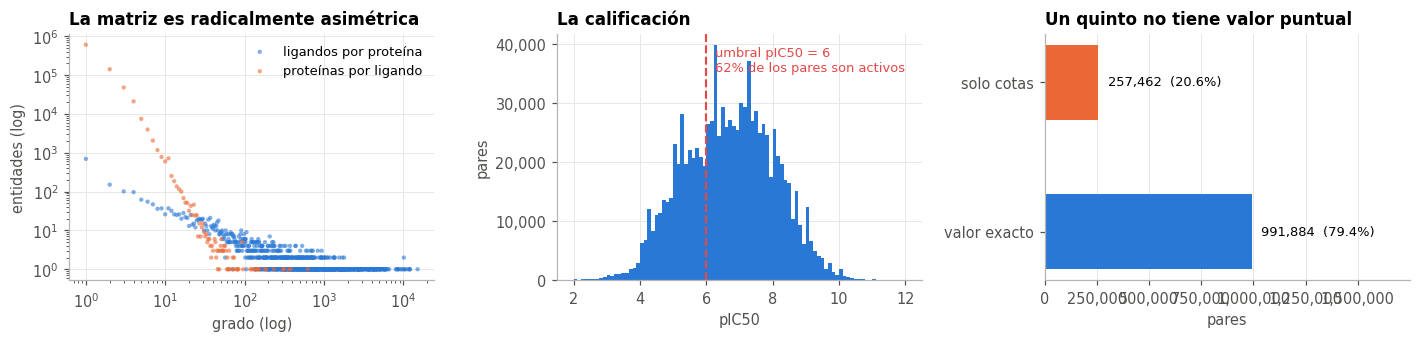

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))

ax = axes[0]
for serie, etq, col in ((lig_por_prot, "ligandos por proteína", AZUL),
                        (prot_por_lig, "proteínas por ligando", NARANJA)):
    vc = serie.value_counts().sort_index()
    ax.scatter(vc.index, vc.values, s=8, color=col, alpha=.6, edgecolors="none", label=etq)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("grado (log)"); ax.set_ylabel("entidades (log)")
ax.legend(fontsize=8.5); ax.set_title("La matriz es radicalmente asimétrica")

ax = axes[1]
ax.hist(I["pIC50"].dropna(), bins=90, color=AZUL)
ax.axvline(UMBRAL, color=ROJO, lw=1.4, ls="--")
ax.annotate(f"umbral pIC50 = {UMBRAL:g}\n{100*PREV:.0f}% de los pares son activos",
            xy=(UMBRAL, ax.get_ylim()[1]*.95), xytext=(6, 0), textcoords="offset points",
            color=ROJO, fontsize=8.5, va="top")
ax.set_xlabel("pIC50"); ax.set_ylabel("pares"); miles(ax)
ax.set_title("La calificación")

ax = axes[2]
vals = [int(I["pIC50"].notna().sum()), int(I["solo_censurado"].sum())]
b = ax.barh(["valor exacto", "solo cotas"], vals, color=[AZUL, NARANJA], height=.5)
for r_, v in zip(b, vals):
    ax.annotate(f"{v:,}  ({pct(v, len(I)):.1f}%)", xy=(v, r_.get_y()+r_.get_height()/2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5)
ax.set_xlim(0, len(I)*1.4); miles(ax, "x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("pares"); ax.set_title("Un quinto no tiene valor puntual")
guardar(fig, "01_datos")

**Lectura.** El panel izquierdo contiene la decisión de diseño más importante del notebook. Cada proteína tiene **363 ligandos** medidos en promedio, pero cada ligando tiene **1.5 proteínas** y el 72.6 % se probó contra una sola. Un ligando con una única interacción no co-ocurre con nada, así que **no hay vecindario colaborativo del lado de los ligandos**: la co-ocurrencia solo existe del lado de las proteínas, y el lado de las moléculas depende por completo de su estructura química. Eso obliga a un modelo híbrido, y no por requisito de la práctica.

El panel derecho marca el otro problema: el 20 % de los pares solo trae cotas del tipo `>10000`, que autorizan la etiqueta `activo` pero no un número. Descartarlos sesgaría todo hacia los compuestos potentes, porque un laboratorio publica el valor exacto cuando el compuesto funciona y una cota cuando no.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Cómo se convierten en números</span></div>

### 4.1 La molécula: huella ECFP4

El algoritmo recorre cada átomo, codifica el vecindario que lo rodea hasta dos enlaces de distancia y prende un bit por cada vecindario distinto. El vector binario de 2048 posiciones dice **de qué fragmentos está hecha la molécula**.

La semejanza entre dos huellas es el **Tanimoto**: $T(a,b) = |a \cap b| / |a \cup b|$, que vale 1 para moléculas idénticas y 0 si no comparten ningún fragmento. Es la definición operativa de "moléculas parecidas" en química medicinal, y es la pieza sobre la que descansa todo el modelo de contenido.

In [4]:
gen = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIO, fpSize=FP_BITS)
CACHE_FP = PROC / f"fp_morgan_r{FP_RADIO}_{FP_BITS}.npz"
CACHE_ID = CACHE_FP.with_suffix(".parquet")

meta = pd.read_parquet(CACHE_ID) if (CACHE_FP.exists() and CACHE_ID.exists()) else None
vale = (meta is not None and len(meta) == len(L)
        and np.array_equal(meta["lig_id"].to_numpy(), L["lig_id"].to_numpy()))
t0 = time.time()
if vale:
    z = np.load(CACHE_FP)
    FP = sp.csr_matrix((z["data"], z["indices"], z["indptr"]), shape=tuple(z["shape"]))
    validos = np.nonzero(meta["_valido"].to_numpy())[0]
    print(f"Huellas leídas de {CACHE_FP.name} en {time.time()-t0:.1f}s")
else:
    filas, cols, validos = [], [], []
    for j, smi in enumerate(L["smiles"].to_numpy()):
        m_ = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
        if m_ is None: continue
        b_ = np.nonzero(gen.GetFingerprintAsNumPy(m_))[0]
        filas.append(np.full(b_.size, len(validos))); cols.append(b_); validos.append(j)
    validos = np.asarray(validos)
    FP = sp.csr_matrix((np.ones(sum(len(c) for c in cols), np.float32),
                        (np.concatenate(filas), np.concatenate(cols))),
                       shape=(len(validos), FP_BITS))
    meta = pd.DataFrame({"lig_id": L["lig_id"].to_numpy(), "_valido": False})
    meta.loc[validos, "_valido"] = True
    sp.save_npz(CACHE_FP, FP); meta.to_parquet(CACHE_ID, index=False)
    print(f"Huellas calculadas en {time.time()-t0:.0f}s y cacheadas")

L = L.iloc[validos].reset_index(drop=True)
I = I[I["lig_id"].isin(set(L["lig_id"]))].reset_index(drop=True)
print(f"Huellas {FP.shape} | bits activos por molécula: mediana "
      f"{int(np.median(FP.getnnz(axis=1)))} ({100*FP.nnz/(FP.shape[0]*FP_BITS):.2f}% de densidad)")
print(f"Pares que sobreviven: {len(I):,}")

# descriptores sobre una muestra, solo para la figura
smp = L.sample(min(N_DESC, len(L)), random_state=SEMILLA)
fil = []
for smi in smp["smiles"].to_numpy():
    m_ = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
    if m_ is not None:
        fil.append([Descriptors.MolWt(m_), Descriptors.MolLogP(m_), Descriptors.TPSA(m_)])
D = pd.DataFrame(fil, columns=["peso_mol", "logp", "tpsa"])

Huellas leídas de fp_morgan_r2_2048.npz en 0.9s
Huellas (830999, 2048) | bits activos por molécula: mediana 58 (2.85% de densidad)
Pares que sobreviven: 1,248,252


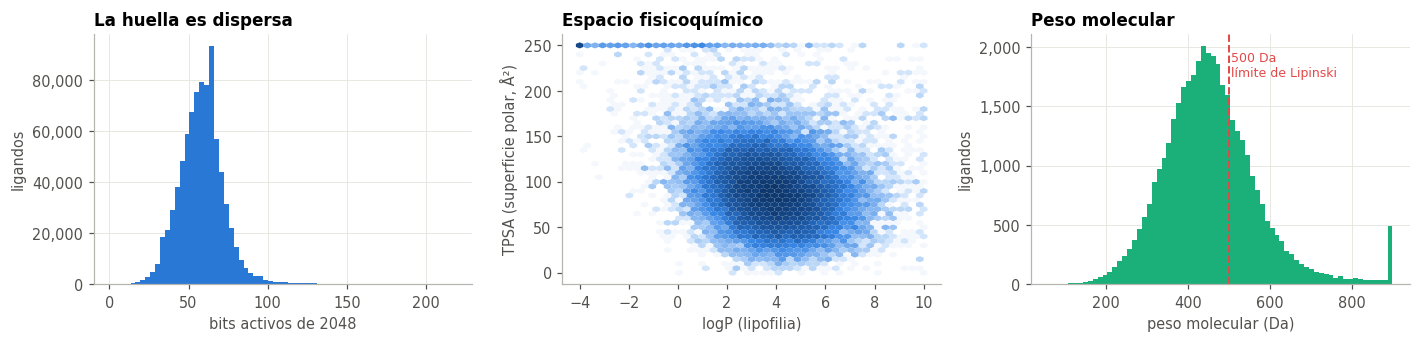

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))

ax = axes[0]
ax.hist(FP.getnnz(axis=1), bins=70, color=AZUL)
ax.set_xlabel(f"bits activos de {FP_BITS}"); ax.set_ylabel("ligandos"); miles(ax)
ax.set_title("La huella es dispersa")

ax = axes[1]
ax.hexbin(D["logp"].clip(-4, 10), D["tpsa"].clip(0, 250), gridsize=45,
          cmap=SEQ_CMAP, bins="log", linewidths=0)
ax.set_xlabel("logP (lipofilia)"); ax.set_ylabel("TPSA (superficie polar, Å²)")
ax.grid(False); ax.set_title("Espacio fisicoquímico")

ax = axes[2]
ax.hist(D["peso_mol"].clip(0, 900), bins=70, color=AQUA)
ax.axvline(500, color=ROJO, lw=1.3, ls="--")
ax.annotate("500 Da\nlímite de Lipinski", xy=(505, ax.get_ylim()[1]*.93),
            color=ROJO, fontsize=8.2, va="top")
ax.set_xlabel("peso molecular (Da)"); ax.set_ylabel("ligandos"); miles(ax)
ax.set_title("Peso molecular")
guardar(fig, "02_moleculas")

**Lectura.** Cada molécula prende unos 58 bits de 2048, así que el 97 % de cada vector es cero: eso permite guardar las huellas como matriz dispersa y calcular el Tanimoto con un producto de matrices en lugar de comparando pares uno a uno.

El peso molecular se amontona por debajo de los 500 Da, el límite de la regla de Lipinski. No es casualidad: BindingDB recoge literatura de química medicinal, donde se sintetiza pensando en ese límite. **El modelo no ve el espacio químico completo, sino el fragmento que a la industria le pareció prometedor**, y conviene recordarlo al leer cualquier resultado.

### 4.2 La proteína: 3-meros de la secuencia

Una secuencia proteica es una cadena sobre un alfabeto de 20 letras. Sus **3-meros** son todas las subcadenas de longitud 3, y la proteína se representa por el vector de frecuencias de los 8,000 posibles. Con `MKVLAA`: `MKV`, `KVL`, `VLA`, `LAA`.

Es *bolsa de palabras* aplicada a proteínas. Funciona porque dos proteínas de la misma familia comparten los motivos conservados que la definen, y el coseno entre sus vectores aproxima la identidad de secuencia **sin tener que alinear** —aquí importa, porque alinear los 5.9 millones de parejas posibles sería prohibitivo.

Limitación que hay que declarar: captura **familia, no bolsillo de unión**. Dos proteínas poco parecidas en conjunto pueden tener sitios activos casi idénticos, y una sola mutación en el residuo correcto cambia por completo qué se une. Corregirlo exigiría estructura tridimensional.

In [6]:
AA = "ACDEFGHIKLMNPQRSTVWY"; IX_AA = {a: i for i, a in enumerate(AA)}
N_KMER = 20 ** K_MER

def vector_kmeros(seq):
    """Frecuencias de los 20^K_MER k-meros. Los símbolos no estándar (X, U, B, Z) se saltan."""
    v = np.zeros(N_KMER, np.float32)
    if not isinstance(seq, str): return v
    s = seq.upper()
    for p in range(len(s) - K_MER + 1):
        idx, ok = 0, True
        for ch in s[p:p + K_MER]:
            j = IX_AA.get(ch)
            if j is None: ok = False; break
            idx = idx * 20 + j
        if ok: v[idx] += 1
    n = v.sum()
    return v / n if n else v

t0 = time.time()
KM = np.vstack([vector_kmeros(s) for s in T["secuencia"].to_numpy()])
nrm = np.linalg.norm(KM, axis=1, keepdims=True); nrm[nrm == 0] = 1
KM_N = (KM / nrm).astype(np.float32)
S_SEQ = (KM_N @ KM_N.T).astype(np.float32); np.fill_diagonal(S_SEQ, 0.0)

# ¿Funciona? El vecino más parecido debería ser de la misma familia.
# Proxy de familia: prefijo del entry name de UniProt (CDK2_HUMAN -> CDK).
fam = (T["entry_name"].astype("string").str.split("_").str[0]
         .str.replace(r"\d+$", "", regex=True).to_numpy())
n_fam = pd.Series(fam).map(pd.Series(fam).value_counts()).to_numpy()
con_hermano = n_fam > 1
acierta = (fam == fam[S_SEQ.argmax(axis=1)]) & con_hermano
azar_fam = float(np.mean((n_fam[con_hermano]-1)/(len(fam)-1)))
TASA_FAM = pct(acierta.sum(), con_hermano.sum())
print(f"{K_MER}-meros: {KM.shape} en {time.time()-t0:.1f}s")
print(f"Proteínas con al menos un hermano de familia: {con_hermano.sum():,} de {len(fam):,}")
print(f"Su vecino más parecido es de la misma familia: {TASA_FAM:.1f}% "
      f"(por azar {100*azar_fam:.2f}% -> {TASA_FAM/(100*azar_fam):.0f}x mejor)")
RES["vecino_misma_familia_pct"] = round(TASA_FAM, 1)

3-meros: (3444, 8000) en 2.7s
Proteínas con al menos un hermano de familia: 1,625 de 3,444
Su vecino más parecido es de la misma familia: 52.2% (por azar 0.12% -> 424x mejor)


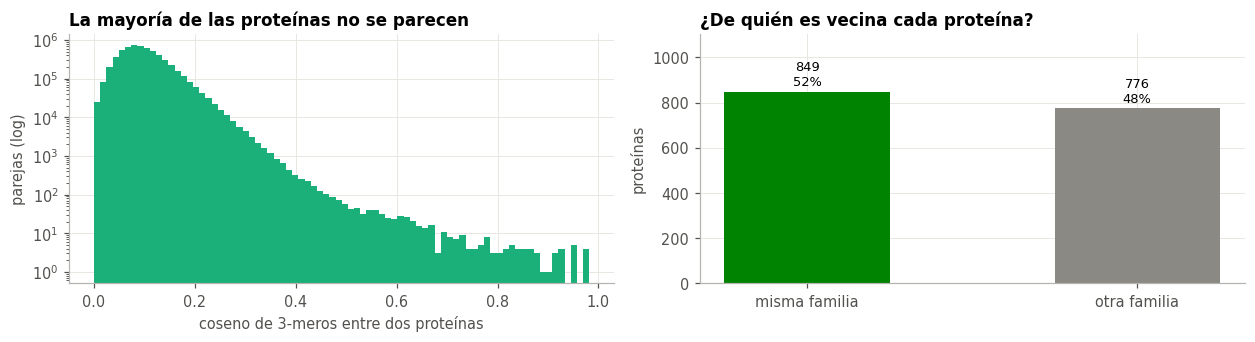

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.2))

ax = axes[0]
ax.hist(S_SEQ[np.triu_indices_from(S_SEQ, k=1)], bins=80, color=AQUA)
ax.set_yscale("log")
ax.set_xlabel(f"coseno de {K_MER}-meros entre dos proteínas")
ax.set_ylabel("parejas (log)"); ax.set_title("La mayoría de las proteínas no se parecen")

ax = axes[1]
alt = [int(acierta.sum()), int(con_hermano.sum()-acierta.sum())]
bb = ax.bar(["misma familia", "otra familia"], alt, color=[VERDE, GRIS], width=.5)
for r_, v in zip(bb, alt):
    ax.annotate(f"{v:,}\n{pct(v, con_hermano.sum()):.0f}%",
                xy=(r_.get_x()+r_.get_width()/2, v), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=8.5)
ax.set_ylabel("proteínas"); ax.set_ylim(0, max(alt)*1.3)
ax.set_title("¿De quién es vecina cada proteína?")
guardar(fig, "03_proteinas")

**Lectura.** El panel derecho es la validación de que la representación sirve: **el vecino más cercano por 3-meros pertenece a la misma familia en más de la mitad de los casos**, cientos de veces por encima de lo que daría el azar. Contar tripletes de aminoácidos recupera señal biológica real, y eso es lo que permite que una proteína con pocas mediciones tenga vecinas útiles de las que aprender.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Partición: por qué no puede ser al azar</span></div>

Un mismo artículo publica decenas de análogos casi idénticos. Si los pares se reparten al azar entre entrenamiento y prueba, el modelo acaba interpolando entre primos hermanos y las métricas salen infladas.

Se usa como principal la **partición temporal** —entrenar con lo publicado hasta un año y predecir lo medido después—, que es la que reproduce el uso real. La **aleatoria** se conserva solo como referencia, para medir cuánto optimismo introduce.

In [8]:
TGT_IX = pd.Series(np.arange(len(T)), index=T["target_id"])
LIG_IX = pd.Series(np.arange(len(L)), index=L["lig_id"])
I["_u"] = TGT_IX.reindex(I["target_id"]).to_numpy()
I["_i"] = LIG_IX.reindex(I["lig_id"]).to_numpy()
I = I[I["_u"].notna() & I["_i"].notna()].copy()
I[["_u", "_i"]] = I[["_u", "_i"]].astype(int)
n_prot, n_lig = len(T), len(L)

anio = I["anio_min"].astype(float)
CORTE = np.nanquantile(anio, 1 - TEST_FRAC)
MASCARA = {"temporal": ((anio <= CORTE).fillna(False) | anio.isna()).to_numpy(bool),
           "aleatoria": rng.random(len(I)) >= TEST_FRAC}

filas = []
for k_, m_ in MASCARA.items():
    vistos = set(I.loc[m_, "lig_id"])
    filas.append({"partición": k_, "train": int(m_.sum()), "test": int((~m_).sum()),
                  "% test con ligando nuevo":
                      round(100*(~I.loc[~m_, "lig_id"].isin(vistos)).mean(), 1)})
display(pd.DataFrame(filas).style.format({"train": "{:,}", "test": "{:,}"}).hide(axis="index"))

M_TR = MASCARA["temporal"]
tr = I[M_TR].reset_index(drop=True)
_t = I[~M_TR].sample(frac=1, random_state=SEMILLA)
te = (_t[_t.groupby("target_id", observed=True).cumcount() < MAX_TEST_POR_PROT]
      .reset_index(drop=True))
te["frio"] = ~te["lig_id"].isin(set(tr["lig_id"]))
uu, ll = te["_u"].to_numpy(), te["_i"].to_numpy()
print(f"\nPrincipal: temporal, train hasta {CORTE:.0f} | train {len(tr):,} | "
      f"test {len(te):,} (tope {MAX_TEST_POR_PROT} por proteína)")
print(f"Pares de test cuyo ligando el modelo NUNCA vio: {100*te['frio'].mean():.1f}%")
RES["particion"] = dict(corte=int(CORTE), train=len(tr), test=len(te),
                        frio_pct=round(100*te["frio"].mean(), 1))

partición,train,test,% test con ligando nuevo
temporal,"1,040,255","207,997",97.800000
aleatoria,"998,530","249,722",53.400000



Principal: temporal, train hasta 2022 | train 1,040,255 | test 107,399 (tope 300 por proteína)
Pares de test cuyo ligando el modelo NUNCA vio: 97.3%


**Lectura.** Como el 72.6 % de los ligandos se midió contra una sola proteína, **el arranque en frío no es un escenario que se elija al partir: es la condición por defecto**. Incluso repartiendo pares al azar, la mitad del test queda con moléculas que el modelo nunca vio, y con la partición temporal es casi todo. Esto adelanta qué va a pasar: el filtrado colaborativo clásico tendrá muy poco espacio donde operar.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Los modelos</span></div>

Cinco modelos, cada uno con un papel claro. Todos producen una puntuación con la que se ordenan los candidatos.

| Modelo | Qué usa | Para qué está |
|---|---|---|
| `azar` | nada | la referencia real: vale la prevalencia, ~0.62 |
| `media_proteina` | la media de la proteína | **control**: no ordena nada dentro de ella, así que su AUC debe salir 0.500 exacto |
| `popularidad` | el pIC50 medio del ligando contra otras proteínas | ¿basta con saber qué moléculas son potentes en general? |
| `colaborativo` | proteínas vecinas que midieron **ese mismo** ligando | el filtrado colaborativo clásico |
| `contenido` | moléculas **parecidas** que **esta** proteína ya midió | el principio de similitud |
| **`híbrido`** | contenido + proteínas vecinas + popularidad | el modelo propuesto |

### Cómo funciona el híbrido

Acumula tres fuentes como numerador y denominador **sin dividir**, lo que permite barrer sus pesos sin recalcular nada:

$$\hat s(u,i) = \frac{\overbrace{\textstyle\sum_{j} T(i,j)\,r(u,j)}^{\text{lo que esta proteína midió}} + \lambda \overbrace{\textstyle\sum_{v}\textstyle\sum_{j} \text{sim}(u,v)\,T(i,j)\,\big(r(v,j)-\mu_v\big)}^{\text{lo que midieron las proteínas vecinas}} + \gamma\, \overbrace{\text{pop}(i)}^{\text{popularidad}} + \varepsilon\,\mu_u}{\text{den}_1 + \lambda\,\text{den}_2 + \gamma\,[\exists\,\text{pop}] + \varepsilon}$$

La clave está en la segunda fuente. El colaborativo clásico pregunta *"¿qué obtuvieron las vecinas con **este** ligando?"* y casi nunca hay respuesta. La reformulación pregunta *"¿qué obtuvieron con ligandos **parecidos** a este?"*, que sí tiene respuesta aunque la molécula sea nueva.

**Qué es una proteína vecina.** Se mezclan las dos definiciones posibles con el parámetro `BETA`:

$$\text{sim}(u,v) = \beta\,\underbrace{\cos(\text{perfil}_u,\text{perfil}_v)}_{\text{midieron los mismos ligandos}} + (1-\beta)\,\underbrace{\cos(\text{kmer}_u,\text{kmer}_v)}_{\text{se parecen como proteínas}}$$

La primera está casi vacía; la segunda **siempre está definida**, y es la que rescata a las proteínas con pocas mediciones.

In [9]:
POP_BITS = np.asarray(FP.getnnz(axis=1), np.float32)
TOPE_CELDAS = 20_000_000

def tanimoto(ia, ib):
    """Matriz |ia| x |ib| de Tanimoto entre huellas."""
    inter = np.asarray((FP[ia] @ FP[ib].T).todense(), np.float32)
    union = POP_BITS[ia][:, None] + POP_BITS[ib][None, :] - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)

def knn(idx_te, idx_tr, y_tr, w_fila=None):
    """Suma ponderada por Tanimoto de los K_VEC_LIG vecinos más parecidos.
    Devuelve (num, den, tanimoto_max) SIN dividir. Procesa por trozos porque la matriz
    completa de una proteína con miles de ligandos no cabe en memoria."""
    n = len(idx_te)
    num = np.zeros(n); den = np.zeros(n); smax = np.zeros(n, np.float32)
    if len(idx_tr) == 0: return num, den, smax
    paso = max(1, int(TOPE_CELDAS // len(idx_tr)))
    for a in range(0, n, paso):
        b = min(a + paso, n); sub = idx_te[a:b]
        Tm = tanimoto(sub, idx_tr)
        Tm[sub[:, None] == idx_tr[None, :]] = 0.0    # un ligando no es su propio vecino
        Tm[Tm < MIN_TANIMOTO] = 0.0
        kk = min(K_VEC_LIG, Tm.shape[1])
        if kk < Tm.shape[1]:
            c_ = np.partition(Tm, -kk, 1)[:, -kk][:, None]
            Tm = np.where(Tm >= c_, Tm, 0.0)
        smax[a:b] = Tm.max(1)
        Wm = Tm if w_fila is None else Tm * w_fila[None, :]
        num[a:b] = Wm @ y_tr; den[a:b] = Wm.sum(1)
    return num, den, smax

def calificacion(df):
    """pIC50 del par. Si solo hay cotas no hay valor puntual, así que se usa un punto
    junto al umbral según 'activo'. Es una imputación declarada, no un dato."""
    y = df["pIC50"].to_numpy(dtype="float32", na_value=np.nan)
    rel = np.where(df["activo"].to_numpy() == 1, UMBRAL + .5, UMBRAL - .5).astype(np.float32)
    return np.where(np.isnan(y), rel, y)

def sim_proteinas(S_col, beta=BETA, k=N_PROT_VEC):
    """Mezcla co-ocurrencia y secuencia, recorta a k vecinas y normaliza las filas."""
    off = ~np.eye(len(S_SEQ), dtype=bool)
    Ss = np.clip(S_SEQ - S_SEQ[off].mean(), 0, None); Ss /= (Ss.max() or 1)
    S = (beta*S_col + (1-beta)*Ss).astype(np.float32); np.fill_diagonal(S, 0.0)
    if k < S.shape[1]:
        c_ = np.partition(S, -k, 1)[:, -k][:, None]; S = np.where(S >= c_, S, 0.0)
    f_ = S.sum(1, keepdims=True)
    return S / np.where(f_ == 0, 1, f_)

def fuentes(base, obj):
    """Las piezas del híbrido con `base` como entrenamiento y `obj` como objetivo."""
    yb = calificacion(base); mub = float(yb.mean())
    mu_u = (pd.Series(yb).groupby(base["_u"].to_numpy()).mean()
              .reindex(range(n_prot)).fillna(mub).to_numpy(np.float32))
    o_u, o_i = obj["_u"].to_numpy(), obj["_i"].to_numpy()
    porp = {p: g for p, g in base.groupby("_u", observed=True)}

    # similitud colaborativa entre proteínas: coseno de perfiles binarios
    Bb = sp.csr_matrix((np.ones(len(base), np.float32), (base["_u"], base["_i"])),
                       shape=(n_prot, n_lig)); Bb.data[:] = 1.0
    nb_ = np.sqrt(np.asarray(Bb.multiply(Bb).sum(1))).ravel(); nb_[nb_ == 0] = 1
    Bn = sp.diags(1/nb_) @ Bb
    S_col = np.asarray((Bn @ Bn.T).todense(), np.float32)
    Ov = np.asarray((Bb @ Bb.T).todense(), np.int32)
    S_col[Ov < MIN_SOLAPE] = 0.0; np.fill_diagonal(S_col, 0.0)
    if K_VEC_PROT < n_prot:
        c_ = np.partition(S_col, -K_VEC_PROT, 1)[:, -K_VEC_PROT][:, None]
        S_col = np.where(S_col >= c_, S_col, 0.0)

    # colaborativo clásico: el MISMO ligando, medido por proteínas vecinas
    Rb = sp.csr_matrix((yb, (base["_u"], base["_i"])), shape=(n_prot, n_lig)).tocsc()
    cf = np.full(len(obj), np.nan, np.float32)
    for r_ in range(len(obj)):
        c = o_i[r_]; a, b = Rb.indptr[c], Rb.indptr[c+1]
        if a == b: continue
        vs, rv = Rb.indices[a:b], Rb.data[a:b]
        w = S_col[o_u[r_], vs]; nz = w > 0
        if not nz.any(): continue
        cf[r_] = mu_u[o_u[r_]] + (w[nz]*(rv[nz]-mu_u[vs[nz]])).sum() / np.abs(w[nz]).sum()

    # fuente 1: moléculas parecidas que ESTA proteína ya midió
    n1 = np.zeros(len(obj)); d1 = np.zeros(len(obj)); smax = np.zeros(len(obj), np.float32)
    for p, g in obj.groupby("_u", observed=True):
        gb = porp.get(p)
        if gb is None or not len(gb): continue
        a_, b_, s_ = knn(g["_i"].to_numpy(), gb["_i"].to_numpy(), calificacion(gb))
        pos = g.index.to_numpy(); n1[pos], d1[pos], smax[pos] = a_, b_, s_

    # fuente 2: proteínas vecinas sobre moléculas parecidas, centradas por su media
    S_prot = sim_proteinas(S_col)
    n2 = np.zeros(len(obj)); d2 = np.zeros(len(obj))
    for p, g in obj.groupby("_u", observed=True):
        vs = np.nonzero(S_prot[p])[0]
        if vs.size == 0: continue
        idx, ys, ws = [], [], []
        for v in vs:
            gv = porp.get(v)
            if gv is None or not len(gv): continue
            if len(gv) > CAP_VECINO: gv = gv.sample(CAP_VECINO, random_state=SEMILLA)
            idx.append(gv["_i"].to_numpy()); ys.append(calificacion(gv) - mu_u[v])
            ws.append(np.full(len(gv), S_prot[p, v], np.float32))
        if not idx: continue
        a_, b_, _ = knn(g["_i"].to_numpy(), np.concatenate(idx), np.concatenate(ys),
                        w_fila=np.concatenate(ws))
        pos = g.index.to_numpy(); n2[pos], d2[pos] = a_, b_

    # fuente 3: popularidad del ligando, solo si alguien más lo midió
    gl = pd.Series(yb).groupby(base["_i"].to_numpy()).agg(["sum", "size"])
    s_l = gl["sum"].reindex(o_i).to_numpy(); c_l = gl["size"].reindex(o_i).to_numpy()
    hay = np.nan_to_num(c_l) > 0
    pop = np.where(hay, (np.nan_to_num(s_l) + 2*mub)/(np.nan_to_num(c_l) + 2), mub)
    return dict(cf=cf, n1=n1, d1=d1, n2=n2, d2=d2, pop=pop, d_pop=hay.astype(float),
                smax=smax, mu_u=mu_u[o_u], mu_prot=mu_u, S_prot=S_prot)

def hibrido(F, lam, gam, eps=EPS):
    """lam = peso de las proteínas vecinas, gam = peso de la popularidad."""
    num = F["n1"] + lam*(F["n2"] + F["d2"]*F["mu_u"]) + gam*F["d_pop"]*F["pop"] + eps*F["mu_u"]
    den = F["d1"] + lam*F["d2"] + gam*F["d_pop"] + eps
    return num / den

t0 = time.time(); F_TE = fuentes(tr, te)
te["tanimoto_max"] = F_TE["smax"]
pred_cf = F_TE["cf"]
pred_cont = np.where(F_TE["d1"] > 0, F_TE["n1"]/np.where(F_TE["d1"] == 0, 1, F_TE["d1"]), np.nan)
MU = float(calificacion(tr).mean())
mu_lig = pd.Series(calificacion(tr)).groupby(tr["_i"].to_numpy()).mean()
print(f"Fuentes calculadas en {time.time()-t0:.0f}s")

frio = te["frio"].to_numpy(); nf = max(int(frio.sum()), 1); nt = max(int((~frio).sum()), 1)
COB = pd.DataFrame({
    "global": [pct(np.isfinite(pred_cf).sum(), len(te)),
               pct(np.isfinite(pred_cont).sum(), len(te)),
               pct(((F_TE["d1"]+F_TE["d2"]) > 0).sum(), len(te))],
    "molécula ya vista": [pct((np.isfinite(pred_cf) & ~frio).sum(), nt),
                          pct((np.isfinite(pred_cont) & ~frio).sum(), nt),
                          pct((((F_TE["d1"]+F_TE["d2"]) > 0) & ~frio).sum(), nt)],
    "molécula nueva": [pct((np.isfinite(pred_cf) & frio).sum(), nf),
                       pct((np.isfinite(pred_cont) & frio).sum(), nf),
                       pct((((F_TE["d1"]+F_TE["d2"]) > 0) & frio).sum(), nf)]},
    index=["colaborativo clásico", "contenido", "híbrido"])
display(COB.style.format("{:.1f}%").background_gradient(cmap="Blues", axis=None)
        .set_caption("Cobertura: ¿en qué fracción de pares el modelo puede decir algo?"))
RES["cobertura"] = json.loads(COB.to_json(orient="index"))

Fuentes calculadas en 23s


,global,molécula ya vista,molécula nueva
colaborativo clásico,1.5%,53.6%,0.0%
contenido,91.0%,87.5%,91.1%
híbrido,99.8%,99.7%,99.8%


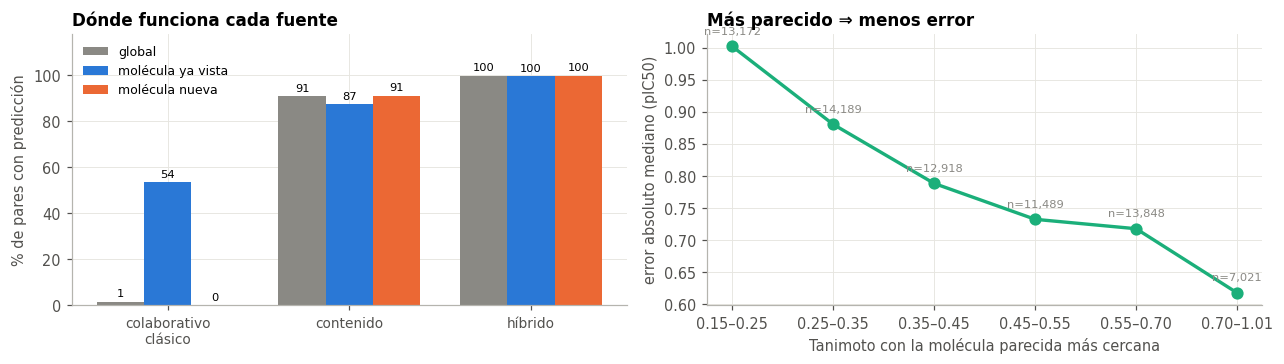

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 3.4))

ax = axes[0]
x = np.arange(3); w = .26
for i_, (c_, col) in enumerate(zip(COB.columns, [GRIS, AZUL, NARANJA])):
    bb = ax.bar(x + (i_-1)*w, COB[c_], width=w, color=col, label=c_)
    ax.bar_label(bb, fmt="%.0f", fontsize=7.5, padding=2)
ax.set_xticks(x); ax.set_xticklabels(["colaborativo\nclásico", "contenido", "híbrido"], fontsize=9)
ax.set_ylabel("% de pares con predicción"); ax.set_ylim(0, 118); ax.legend(fontsize=8.2)
ax.set_title("Dónde funciona cada fuente")

ax = axes[1]
m_ = np.isfinite(pred_cont) & te["pIC50"].notna().to_numpy()
err = np.abs(pred_cont[m_] - te.loc[m_, "pIC50"].to_numpy())
s_ = te.loc[m_, "tanimoto_max"].to_numpy()
bins = np.array([.15, .25, .35, .45, .55, .7, 1.01]); etq, med, cnt = [], [], []
for a, b in zip(bins[:-1], bins[1:]):
    sel = (s_ >= a) & (s_ < b)
    if sel.sum() >= 50:
        etq.append(f"{a:.2f}–{b:.2f}"); med.append(np.median(err[sel])); cnt.append(int(sel.sum()))
ax.plot(etq, med, "o-", color=AQUA, lw=2.2, ms=7)
for i_, (v_, c_) in enumerate(zip(med, cnt)):
    ax.annotate(f"n={c_:,}", xy=(i_, v_), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=7.5, color=GRIS)
ax.set_xlabel("Tanimoto con la molécula parecida más cercana")
ax.set_ylabel("error absoluto mediano (pIC50)")
ax.set_title("Más parecido ⇒ menos error")
guardar(fig, "04_cobertura")

**Lectura.** Estos dos paneles son el argumento central del notebook.

A la izquierda, **el colaborativo clásico no puede predecir ni un solo par con molécula nueva**: si nadie midió ese ligando, no hay nada que promediar. No es un defecto de implementación, es la estructura de la matriz. Reformular la pregunta hacia *moléculas parecidas* lleva la cobertura de 0 % a prácticamente 100 % en esos mismos pares. El híbrido se justifica por **complementariedad**, no por promediar.

A la derecha, la validación del supuesto: el error baja de forma monótona conforme la molécula parecida disponible se acerca a la consultada. Si la curva saliera plana, la huella no estaría aportando nada. De paso da la regla de uso: **una recomendación apoyada en un Tanimoto bajo es poco fiable**, y por eso la §9 muestra esa columna junto a cada sugerencia.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Ajuste de los dos pesos</span></div>

$\lambda$ y $\gamma$ se eligen sobre una **validación interna** extraída del entrenamiento con el mismo criterio temporal. Elegirlos mirando el test sería fuga de información: los números finales saldrían optimistas y dejarían de estimar desempeño fuera de muestra.

El criterio es `NDCG@10`, porque la tarea es ordenar. Y el barrido **sale gratis**: como las tres fuentes se guardaron sin dividir, probar un par de pesos es una división sobre vectores ya calculados.

Validación interna: train 894,510 | val 145,745  [39s]

λ = 2  (peso de las proteínas vecinas)
γ = 3  (peso de la popularidad del ligando)
Mejora sobre usar solo el contenido propio (λ=γ=0): +2.74%


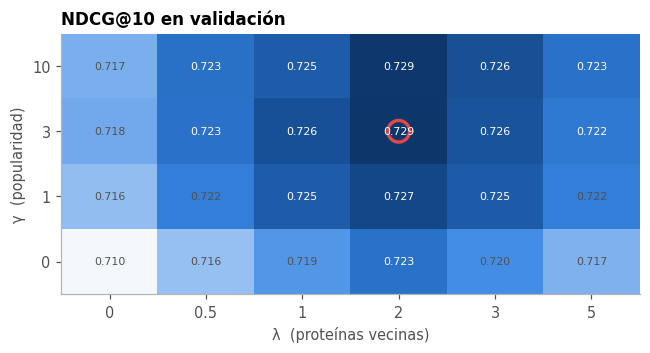

In [11]:
def ndcg_prot(df, score, k=TOP_K):
    """NDCG@k promediado sobre proteínas. Baraja antes de ordenar para romper empates."""
    d = df.assign(_sc=np.asarray(score, float)).sample(frac=1, random_state=SEMILLA)
    mn = d["_sc"].min(); d["_sc"] = d["_sc"].fillna(mn-1 if np.isfinite(mn) else 0.0)
    out = []
    for _, g in d.groupby("target_id", observed=True):
        if len(g) < MIN_TEST_LIG: continue
        y = g["activo"].to_numpy()
        if y.sum() == 0 or y.sum() == len(y): continue
        ys = g.sort_values("_sc", ascending=False)["activo"].to_numpy()
        kk = min(k, len(ys)); disc = 1/np.log2(np.arange(2, kk+2))
        idcg = (np.sort(y)[::-1][:kk]*disc).sum()
        if idcg > 0: out.append((ys[:kk]*disc).sum()/idcg)
    return float(np.mean(out)) if out else np.nan

a_ = tr["anio_min"].astype(float); c_ = np.nanquantile(a_, 1-TEST_FRAC)
m_val = ((a_ <= c_).fillna(False) | a_.isna()).to_numpy(bool)
tr2, va = tr[m_val].reset_index(drop=True), tr[~m_val].reset_index(drop=True)
t0 = time.time(); F_VAL = fuentes(tr2, va)
print(f"Validación interna: train {len(tr2):,} | val {len(va):,}  [{time.time()-t0:.0f}s]")

rej = pd.DataFrame([(lam, gam, ndcg_prot(va, hibrido(F_VAL, lam, gam)))
                    for lam in LAMBDAS for gam in GAMMAS],
                   columns=["lambda", "gamma", "ndcg"])
LAM, GAM = (float(rej.loc[rej["ndcg"].idxmax(), "lambda"]),
            float(rej.loc[rej["ndcg"].idxmax(), "gamma"]))
base_ndcg = float(rej[(rej["lambda"] == 0) & (rej["gamma"] == 0)]["ndcg"].iloc[0])
print(f"\nλ = {LAM:g}  (peso de las proteínas vecinas)")
print(f"γ = {GAM:g}  (peso de la popularidad del ligando)")
print(f"Mejora sobre usar solo el contenido propio (λ=γ=0): "
      f"{100*(rej['ndcg'].max()-base_ndcg)/base_ndcg:+.2f}%")
pred_hib = hibrido(F_TE, LAM, GAM)
RES["pesos"] = dict(lam=LAM, gam=GAM)

fig, ax = plt.subplots(figsize=(6, 3.3))
piv = rej.pivot(index="gamma", columns="lambda", values="ndcg")
im = ax.imshow(piv.values, cmap=SEQ_CMAP, aspect="auto", origin="lower")
for i_ in range(piv.shape[0]):
    for j_ in range(piv.shape[1]):
        ax.text(j_, i_, f"{piv.values[i_, j_]:.3f}", ha="center", va="center", fontsize=7.2,
                color="white" if piv.values[i_, j_] > piv.values.mean() else "#52514e")
ax.scatter([list(piv.columns).index(LAM)], [list(piv.index).index(GAM)],
           marker="o", s=200, facecolors="none", edgecolors=ROJO, linewidths=2.2)
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"{v:g}" for v in piv.columns])
ax.set_yticks(range(len(piv.index))); ax.set_yticklabels([f"{v:g}" for v in piv.index])
ax.set_xlabel("λ  (proteínas vecinas)"); ax.set_ylabel("γ  (popularidad)")
ax.grid(False); ax.set_title(f"NDCG@{TOP_K} en validación")
guardar(fig, "05_pesos")

**Lectura.** La esquina inferior izquierda ($\lambda=\gamma=0$) es el modelo de contenido puro, y el máximo está lejos de ahí: **las proteínas vecinas aportan señal real**. Que el óptimo de $\lambda$ no caiga en el borde del barrido confirma que el rango explorado es suficiente.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Resultados</span></div>

La tarea es ordenar, así que las métricas se calculan **por proteína** y se promedian entre proteínas; promediar sobre pares dejaría que las pocas proteínas con miles de mediciones dominen.

| Métrica | Qué dice | Referencia |
|---|---|---|
| `precision@10` | de los 10 recomendados, qué fracción es activa | el azar vale la prevalencia, ~0.62 |
| `NDCG@10` | igual, premiando poner los activos arriba | 1 es perfecto |
| `enriquecimiento` | `precision@10` / prevalencia | **1× = azar**, y tiene un techo |
| `AUC` | probabilidad de ordenar un activo sobre un inactivo | 0.5 = azar |
| `RMSE` | error en pIC50 donde hay valor exacto | piso ~0.5 por ruido experimental |

**El techo del enriquecimiento.** Si una proteína tiene solo 3 activos y $k=10$, el mejor ranking posible da `precision@10 = 0.3`. Reportar enriquecimiento sin su techo hace que un resultado decente parezca mediocre, así que la tabla incluye el **% del margen** recorrido.

In [12]:
def evaluar(df, score, nombre, k=TOP_K):
    """Métricas de ranking por proteína. Una fila por proteína evaluable."""
    d = df.assign(_sc=np.asarray(score, float)).sample(frac=1, random_state=SEMILLA)
    d["_cub"] = np.isfinite(d["_sc"])
    mn = d["_sc"].min(); d["_sc"] = d["_sc"].fillna(mn-1 if np.isfinite(mn) else 0.0)
    filas = []
    for pid, g in d.groupby("target_id", observed=True):
        if len(g) < MIN_TEST_LIG: continue
        ya = g["activo"].to_numpy()
        if ya.sum() == 0 or ya.sum() == len(ya): continue
        gs = g.sort_values("_sc", ascending=False)
        y = gs["activo"].to_numpy(); kk = min(k, len(y))
        prev = y.mean(); prec = y[:kk].mean()
        disc = 1/np.log2(np.arange(2, kk+2))
        idcg = (np.sort(y)[::-1][:kk]*disc).sum()
        mm = gs["pIC50"].notna().to_numpy() & gs["_cub"].to_numpy()
        rmse = np.nan
        if mm.sum() >= 3:
            rmse = float(np.sqrt(np.mean((gs.loc[mm, "pIC50"].to_numpy()
                                          - gs.loc[mm, "_sc"].to_numpy())**2)))
        filas.append(dict(target_id=pid, n=len(y), prevalencia=prev, cobertura=gs["_cub"].mean(),
                          **{f"precision@{k}": prec, f"ndcg@{k}": (y[:kk]*disc).sum()/idcg
                             if idcg > 0 else np.nan},
                          enriquecimiento=prec/prev if prev > 0 else np.nan,
                          techo=(min(kk, int(ya.sum()))/kk)/prev if prev > 0 else np.nan,
                          auc=roc_auc_score(y, gs["_sc"].to_numpy()), rmse=rmse))
    r = pd.DataFrame(filas); r.insert(0, "modelo", nombre); return r

MODELOS = {
    "azar":           rng.random(len(te)),
    "media_proteina": F_TE["mu_prot"][uu],
    "popularidad":    mu_lig.reindex(ll).fillna(MU).to_numpy(),
    "colaborativo":   pred_cf,
    "contenido":      pred_cont,
    "híbrido":        pred_hib,
}
det = pd.concat([evaluar(te, s, n) for n, s in MODELOS.items()], ignore_index=True)
det.loc[det["modelo"] == "azar", "rmse"] = np.nan

MET = ["cobertura", f"precision@{TOP_K}", f"ndcg@{TOP_K}", "enriquecimiento", "auc", "rmse"]
tabla = det.groupby("modelo", observed=True)[MET].mean().reindex(MODELOS.keys())
TECHO = float(det["techo"].mean())
tabla["% del margen"] = 100*(tabla["enriquecimiento"]-1)/(TECHO-1)
PREV_TE = float(det["prevalencia"].mean())

print(f"Proteínas evaluadas: {det['target_id'].nunique():,} | "
      f"prevalencia media {PREV_TE:.3f} = lo que obtiene el azar")
print(f"Techo del enriquecimiento: {TECHO:.3f}×  <- ningún modelo puede pasar de aquí\n")
display(tabla.style.format({"cobertura": "{:.1%}", f"precision@{TOP_K}": "{:.4f}",
    f"ndcg@{TOP_K}": "{:.4f}", "enriquecimiento": "{:.3f}×", "auc": "{:.4f}",
    "rmse": "{:.3f}", "% del margen": "{:.1f}%"}, na_rep="—")
    .background_gradient(cmap="Blues", subset=[f"ndcg@{TOP_K}", "auc"]))
RES["tabla"] = json.loads(tabla.to_json(orient="index"))
RES["techo"] = round(TECHO, 4); RES["prevalencia_test"] = round(PREV_TE, 4)

Proteínas evaluadas: 668 | prevalencia media 0.632 = lo que obtiene el azar
Techo del enriquecimiento: 2.320×  <- ningún modelo puede pasar de aquí



,cobertura,precision@10,ndcg@10,enriquecimiento,auc,rmse,% del margen
modelo,,,,,,,
azar,100.0%,0.6356,0.6569,1.001×,0.5037,—,0.1%
media_proteina,100.0%,0.6307,0.6518,0.984×,0.5000,1.190,-1.2%
popularidad,100.0%,0.6376,0.6604,1.014×,0.5079,1.228,1.0%
colaborativo,1.8%,0.6308,0.6547,1.029×,0.5014,1.339,2.2%
contenido,90.8%,0.6904,0.7190,1.158×,0.5977,1.139,12.0%
híbrido,100.0%,0.6999,0.7369,1.216×,0.6166,1.112,16.3%


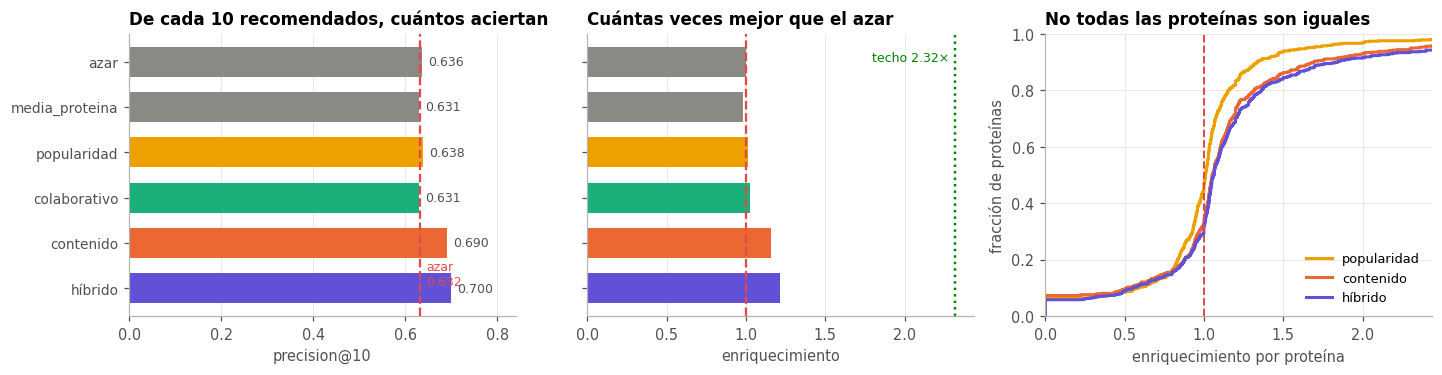

In [13]:
orden = list(MODELOS.keys())
colores = [GRIS, GRIS, AMARILLO, AQUA, NARANJA, VIOLETA]

fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.5))

ax = axes[0]
v = tabla[f"precision@{TOP_K}"].reindex(orden); yy = np.arange(len(orden))[::-1]
ax.barh(yy, v, color=colores, height=.66)
ax.axvline(PREV_TE, color=ROJO, lw=1.5, ls="--")
ax.annotate(f"azar\n{PREV_TE:.3f}", xy=(PREV_TE, 0), xytext=(4, 0),
            textcoords="offset points", color=ROJO, fontsize=8.2, va="bottom")
for y_, x_ in zip(yy, v):
    ax.annotate(f"{x_:.3f}", xy=(x_, y_), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8.2, color="#52514e")
ax.set_yticks(yy); ax.set_yticklabels(orden, fontsize=9)
ax.set_xlim(0, v.max()*1.2); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"precision@{TOP_K}"); ax.set_title("De cada 10 recomendados, cuántos aciertan")

ax = axes[1]
e = tabla["enriquecimiento"].reindex(orden)
ax.barh(yy, e, color=colores, height=.66)
ax.axvline(1, color=ROJO, lw=1.5, ls="--")
ax.axvline(TECHO, color=VERDE, lw=1.6, ls=":")
ax.annotate(f"techo {TECHO:.2f}×", xy=(TECHO, len(orden)-1), xytext=(-4, 0),
            textcoords="offset points", ha="right", color=VERDE, fontsize=8.2)
ax.set_yticks(yy); ax.set_yticklabels([]); ax.grid(axis="y", visible=False)
ax.set_xlabel("enriquecimiento"); ax.set_title("Cuántas veces mejor que el azar")

ax = axes[2]
for m_, col in zip(["popularidad", "contenido", "híbrido"], [AMARILLO, NARANJA, VIOLETA]):
    s = det[det["modelo"] == m_]["enriquecimiento"].dropna()
    if len(s): ax.ecdf(s, color=col, lw=2, label=m_)
ax.axvline(1, color=ROJO, lw=1.3, ls="--")
ax.set_xlim(0, min(TECHO*1.05, det["enriquecimiento"].max()))
ax.set_xlabel("enriquecimiento por proteína"); ax.set_ylabel("fracción de proteínas")
ax.legend(fontsize=8.5, loc="lower right"); ax.set_title("No todas las proteínas son iguales")
guardar(fig, "06_resultados")

In [14]:
# ¿Cuánto infla la partición aleatoria? Se reentrena lo esencial con ella.
t0 = time.time()
m_al = MASCARA["aleatoria"]
tr_al = I[m_al].reset_index(drop=True)
_x = I[~m_al].sample(frac=1, random_state=SEMILLA)
te_al = (_x[_x.groupby("target_id", observed=True).cumcount() < MAX_TEST_POR_PROT]
         .reset_index(drop=True))
F_AL = fuentes(tr_al, te_al)
cmp_ = []
for nm, sc in (("contenido", np.where(F_AL["d1"] > 0,
                                      F_AL["n1"]/np.where(F_AL["d1"] == 0, 1, F_AL["d1"]), np.nan)),
               ("híbrido", hibrido(F_AL, LAM, GAM))):
    r = evaluar(te_al, sc, nm)
    cmp_.append({"modelo": nm, "partición": "aleatoria", "prevalencia": r["prevalencia"].mean(),
                 "enriquecimiento": r["enriquecimiento"].mean()})
for nm in ("contenido", "híbrido"):
    s = det[det["modelo"] == nm]
    cmp_.append({"modelo": nm, "partición": "temporal", "prevalencia": s["prevalencia"].mean(),
                 "enriquecimiento": s["enriquecimiento"].mean()})
cmp_ = pd.DataFrame(cmp_)
print(f"Reentrenado con la partición aleatoria en {time.time()-t0:.0f}s\n")
display(cmp_.pivot(index="modelo", columns="partición", values="enriquecimiento")
        [["aleatoria", "temporal"]].style.format("{:.3f}×")
        .set_caption("Enriquecimiento: la partición aleatoria frente a la temporal"))
inf = cmp_.pivot(index="modelo", columns="partición", values="enriquecimiento")
f_ = (inf["aleatoria"]-1)/(inf["temporal"]-1)
print(f"La partición aleatoria sobreestima la ventaja sobre el azar en un "
      f"{100*(f_.mean()-1):+.0f}% respecto de la temporal.")
RES["inflacion_aleatoria"] = json.loads(cmp_.to_json(orient="records"))

Reentrenado con la partición aleatoria en 44s



partición,aleatoria,temporal
modelo,,
contenido,1.760×,1.158×
híbrido,1.758×,1.216×


La partición aleatoria sobreestima la ventaja sobre el azar en un +316% respecto de la temporal.


**Lectura.** Tres cosas, en orden de importancia.

**Las referencias no se superan solas.** `media_proteina` da AUC exactamente 0.500 —el control pasa, la evaluación no infla nada— y `popularidad` se queda pegada al azar. Eso significa que saber *"esta proteína es fácil de inhibir"* o *"esta molécula es potente en general"* **no sirve para recomendar**: lo único que informa es la interacción entre una proteína concreta y una molécula concreta, que es justo lo que ninguna referencia puede representar.

**El colaborativo clásico empata con el azar por falta de cobertura**, no por mal diseño: solo alcanza a opinar sobre una fracción mínima de los pares. Los modelos que usan la estructura química se separan con claridad.

**La partición aleatoria infla.** Repartir pares al azar deja análogos del mismo artículo a ambos lados del corte, y el enriquecimiento sube mucho sin que el modelo haya mejorado. Es la razón de reportar la temporal como resultado principal.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">9. ¿Acierta también el valor?</span></div>

Las métricas anteriores miden el **orden**. Esta sección comprueba si el `pIC50` predicho guarda relación con el medido, que es con lo que compara la literatura de predicción de afinidad.

Hay una trampa que conviene enseñar: la correlación calculada sobre **todos los pares juntos** incluye las diferencias de nivel *entre* proteínas. Un modelo que solo acertara qué proteínas son fáciles de inhibir ya saldría con correlación alta sin ordenar nada dentro de ninguna. La correlación **dentro de cada proteína** elimina ese efecto y es la que mide lo que interesa.

In [15]:
def correlaciones(nombre, score, min_n=20):
    """Pearson agrupada (todos los pares juntos) y dentro de cada proteína."""
    s = np.asarray(score, float)
    m = te["pIC50"].notna().to_numpy() & np.isfinite(s)
    if m.sum() < 10 or s[m].std() < 1e-9: return None
    y = te.loc[m, "pIC50"].to_numpy(); x = s[m]
    r_ag, p_ag = stats.pearsonr(x, y)
    d = te.loc[m].assign(_sc=x); rs, ns = [], []
    for _, g in d.groupby("target_id", observed=True):
        if len(g) < min_n: continue
        a_, b_ = g["pIC50"].to_numpy(), g["_sc"].to_numpy()
        if a_.std() < 1e-9 or b_.std() < 1e-9: continue
        rs.append(stats.pearsonr(b_, a_)[0]); ns.append(len(g))
    rs = np.asarray(rs); ns = np.asarray(ns)
    r_den = float(np.tanh(np.average(np.arctanh(np.clip(rs, -.999, .999)), weights=ns-3))) \
        if len(rs) else np.nan
    return dict(modelo=nombre, cobertura=float(m.mean()), pares=int(m.sum()),
                r_agrupada=r_ag, p_valor=p_ag, r_dentro=r_den,
                proteinas=len(rs), pct_positiva=100*np.mean(rs > 0) if len(rs) else np.nan,
                _rs=rs)

COR = [c for c in (correlaciones(n, s) for n, s in MODELOS.items()) if c is not None]
dfc = pd.DataFrame([{k: v for k, v in c.items() if not k.startswith("_")}
                    for c in COR]).set_index("modelo")
display(dfc.style.format({"cobertura": "{:.1%}", "pares": "{:,.0f}", "r_agrupada": "{:.4f}",
    "p_valor": "{:.2g}", "r_dentro": "{:.4f}", "proteinas": "{:,.0f}",
    "pct_positiva": "{:.1f}%"}, na_rep="—")
    .background_gradient(cmap="Blues", subset=["r_agrupada", "r_dentro"]))

BC = max([c for c in COR if c["cobertura"] > .5 and c["proteinas"] >= 30
          and np.isfinite(c["r_dentro"]) and c["modelo"] != "azar"],
         key=lambda c: c["r_dentro"])
print(f"\nMejor correlación dentro de proteína: {BC['modelo']}")
print(f"  agrupada r = {BC['r_agrupada']:.3f}  (n = {BC['pares']:,}, p = {BC['p_valor']:.2g})")
print(f"  dentro de proteína r = {BC['r_dentro']:.3f}  sobre {BC['proteinas']} proteínas, "
      f"{BC['pct_positiva']:.0f}% de ellas con r > 0")
RES["correlacion"] = json.loads(dfc.to_json(orient="index"))

,cobertura,pares,r_agrupada,p_valor,r_dentro,proteinas,pct_positiva
modelo,,,,,,,
azar,74.5%,"79,988",0.0032,0.37,0.0002,611,48.3%
media_proteina,74.5%,"79,988",0.3000,0,—,0,—
popularidad,74.5%,"79,988",0.0676,1.4e-81,0.0698,302,63.9%
colaborativo,0.9%,987,0.3161,2.4e-24,0.9099,7,85.7%
contenido,67.6%,"72,637",0.4219,0,0.2297,558,73.5%
híbrido,74.5%,"79,988",0.4199,0,0.2335,611,71.8%



Mejor correlación dentro de proteína: híbrido
  agrupada r = 0.420  (n = 79,988, p = 0)
  dentro de proteína r = 0.233  sobre 611 proteínas, 72% de ellas con r > 0


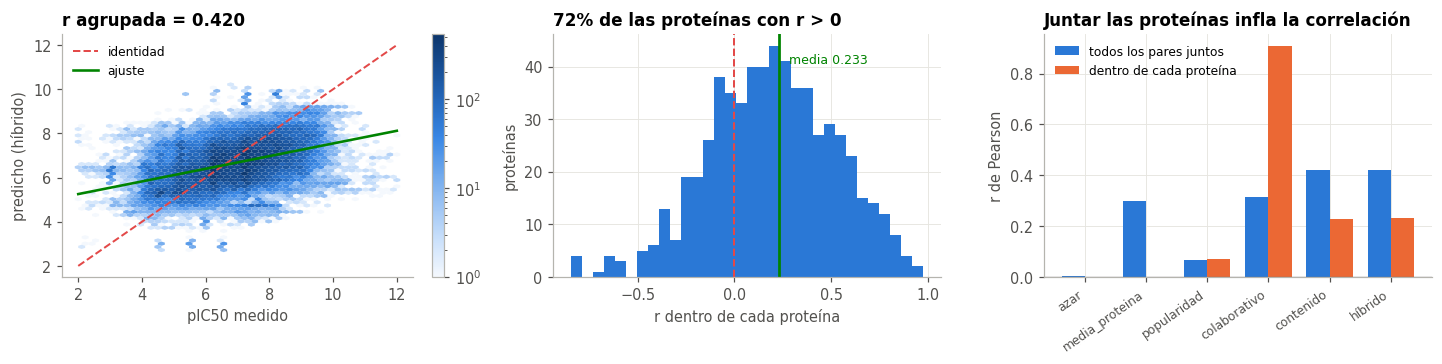

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.4))
sc = np.asarray(MODELOS[BC["modelo"]], float)
m_ = te["pIC50"].notna().to_numpy() & np.isfinite(sc)
yv, xv = te.loc[m_, "pIC50"].to_numpy(), sc[m_]

ax = axes[0]
hb = ax.hexbin(yv, xv, gridsize=46, cmap=SEQ_CMAP, bins="log", linewidths=0)
lim = [float(yv.min()), float(yv.max())]
ax.plot(lim, lim, color=ROJO, lw=1.3, ls="--", label="identidad")
b1, b0 = np.polyfit(yv, xv, 1)
ax.plot(lim, [b0+b1*lim[0], b0+b1*lim[1]], color=VERDE, lw=1.7, label="ajuste")
ax.set_xlabel("pIC50 medido"); ax.set_ylabel(f"predicho ({BC['modelo']})")
ax.grid(False); ax.legend(fontsize=8); ax.set_title(f"r agrupada = {BC['r_agrupada']:.3f}")
plt.colorbar(hb, ax=ax, fraction=.046)

ax = axes[1]
ax.hist(BC["_rs"], bins=32, color=AZUL)
ax.axvline(0, color=ROJO, lw=1.3, ls="--")
ax.axvline(BC["r_dentro"], color=VERDE, lw=1.8)
ax.annotate(f"media {BC['r_dentro']:.3f}", xy=(BC["r_dentro"], ax.get_ylim()[1]*.92),
            xytext=(6, 0), textcoords="offset points", color=VERDE, fontsize=8.2, va="top")
ax.set_xlabel("r dentro de cada proteína"); ax.set_ylabel("proteínas")
ax.set_title(f"{BC['pct_positiva']:.0f}% de las proteínas con r > 0")

ax = axes[2]
cc = dfc.loc[[m for m in MODELOS if m in dfc.index], ["r_agrupada", "r_dentro"]]
x = np.arange(len(cc)); w = .38
ax.bar(x-w/2, cc["r_agrupada"].fillna(0), width=w, color=AZUL, label="todos los pares juntos")
ax.bar(x+w/2, cc["r_dentro"].fillna(0), width=w, color=NARANJA, label="dentro de cada proteína")
ax.axhline(0, color="#52514e", lw=.8)
ax.set_xticks(x); ax.set_xticklabels(cc.index, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("r de Pearson"); ax.legend(fontsize=8)
ax.set_title("Juntar las proteínas infla la correlación")
guardar(fig, "07_correlacion")

**Lectura.** El panel derecho enseña la trampa con un ejemplo que no admite discusión: **`media_proteina` consigue una correlación agrupada alta**, pese a que asigna la misma puntuación a todos los candidatos de una proteína y por tanto no ordena absolutamente nada —su AUC es 0.500 exacto—. Su correlación *dentro* de proteína no existe, porque no hay variación que correlacionar. Un modelo inútil para la tarea puede exhibir una correlación excelente si se reporta mal.

Sobre la magnitud: la correlación dentro de proteína es modesta, y hay una razón de fondo. El **19.8 %** de los pares medidos más de una vez discrepa en más de una unidad de `pIC50` entre laboratorios. Ese ruido experimental pone un techo a cualquier correlación alcanzable y es también el motivo de que el RMSE no pueda bajar de ~0.5. La correlación observada hay que juzgarla contra ese techo, no contra 1.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">10. El recomendador en uso</span></div>

Todo lo anterior se encapsula en una función. Junto a cada sugerencia van dos columnas que deciden si es creíble:

- **`tanimoto_max`** — cuánto se parece el candidato a la molécula más próxima que el modelo pudo usar. Por la curva de la §6, por debajo de ~0.3 conviene desconfiar.
- **`nueva`** — si el modelo nunca había visto esa molécula.

In [17]:
nom_lig = L.set_index("lig_id")["nombre"]
nom_tgt = T.set_index("target_id")["nombre"]
smi_lig = L.set_index("lig_id")["smiles"]

def recomendar(target_id, k=TOP_K):
    """Mejores k ligandos para una proteína, entre sus candidatos del conjunto de prueba
    (los únicos con verdad conocida, así que permiten verificar el acierto)."""
    g = te[te["target_id"] == target_id]
    if not len(g): raise ValueError(f"{target_id} no tiene candidatos en el test")
    d = pd.DataFrame({
        "ligando": [str(nom_lig.get(x, x))[:38] for x in g["lig_id"]],
        "lig_id": g["lig_id"].to_numpy(),
        "pIC50_pred": np.asarray(pred_hib, float)[g.index.to_numpy()],
        "pIC50_real": g["pIC50"].to_numpy(),
        "activo_real": g["activo"].to_numpy(),
        "nueva": g["frio"].to_numpy(),
        "tanimoto_max": g["tanimoto_max"].to_numpy()})
    return d.sort_values("pIC50_pred", ascending=False).head(k).reset_index(drop=True)

def dibujar(filas, titulo, por_fila=5):
    """Dibuja las moléculas recomendadas con su predicción y, si se conoce, el valor real."""
    ms, lg = [], []
    for _, r_ in filas.iterrows():
        smi = smi_lig.get(r_["lig_id"])
        m_ = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
        if m_ is None: continue
        ms.append(m_)
        real = "" if pd.isna(r_["pIC50_real"]) else f" | real {r_['pIC50_real']:.1f}"
        lg.append(f"pred {r_['pIC50_pred']:.2f}{real}")
    if not ms: print("(sin estructuras dibujables)"); return None
    print(titulo)
    return Draw.MolsToGridImage(ms, legends=lg, molsPerRow=por_fila, subImgSize=(230, 190))

mejores = (det[det["modelo"] == "híbrido"].dropna(subset=["enriquecimiento"])
           .sort_values("n", ascending=False)["target_id"].tolist())
EJEMPLOS = mejores[:2]
for pid in EJEMPLOS:
    g = te[te["target_id"] == pid]
    r = recomendar(pid)
    print("=" * 100)
    print(f"{pid} — {str(nom_tgt.get(pid, ''))[:70]}")
    print(f"{len(g):,} candidatos | {100*g['activo'].mean():.0f}% de ellos son activos "
          f"(= lo que acertaría el azar)")
    display(r.style.format({"pIC50_pred": "{:.2f}", "pIC50_real": "{:.2f}",
                            "activo_real": "{:.0f}", "tanimoto_max": "{:.2f}"},
                           na_rep="solo cota").hide(axis="index"))
    print(f"precision@{len(r)} de la recomendación = {r['activo_real'].mean():.2f}")

Q9Y5Y9 — Sodium channel protein type 10 subunit alpha
300 candidatos | 80% de ellos son activos (= lo que acertaría el azar)


ligando,lig_id,pIC50_pred,pIC50_real,activo_real,nueva,tanimoto_max
"US12441703, Compound 43",UQDQWWUQYIRJGY-UHFFFAOYSA,8.34,7.89,1,True,0.70
"US12440481, Compound 28",MJZAHSDLWJMIRX-UHFFFAOYSA,8.31,solo cota,0,True,0.59
"4-[[6-(3,4-Difluoro-2-Methoxy-Phenoxy)",ULDINKYTPULHGZ-UHFFFAOYSA,8.26,8.05,1,True,0.62
"US12441703, Compound 314",WUSVGWFZTLBEIE-UHFFFAOYSA,8.25,8.19,1,True,0.75
"US12441703, Compound 331",GILROAMHXNNRQX-UHFFFAOYSA,8.24,8.34,1,True,0.66
"US12441703, Compound 180",CKHMLATUNQYPEI-UHFFFAOYSA,8.23,6.29,1,True,0.63
"US12441703, Compound 50",CPFVLSJEHHFDKA-UHFFFAOYSA,8.22,7.48,1,True,0.63
"US12441703, Compound 34",RYBNDOLYSMUEMX-UHFFFAOYSA,8.22,6.92,1,True,0.70
"US12441703, Compound 36",GDCFXFMQMZHFAE-UHFFFAOYSA,8.21,6.75,1,True,0.61
"US12441703, Compound 365",JLAJSPQWQJSYTA-UHFFFAOYSA,8.21,7.30,1,True,0.73


precision@10 de la recomendación = 0.90
C9J9Y7 — Potassium sodium-activated channel subfamily T member 1
300 candidatos | 88% de ellos son activos (= lo que acertaría el azar)


ligando,lig_id,pIC50_pred,pIC50_real,activo_real,nueva,tanimoto_max
"US20250313548, Compound I-183a",CETQYROBKRXINH-UHFFFAOYSA,7.20,6.12,1,True,0.00
"US20250313548, Compound I-284a",SXKASWZEHKPPLR-UHFFFAOYSA,7.12,solo cota,1,True,0.00
"US20250313548, Compound I-301a",SHKXCTHUDGUCQI-UHFFFAOYSA,7.12,solo cota,1,True,0.00
"US20250313548, Compound I-285a",BETFZBYCJHTDSD-UHFFFAOYSA,7.10,solo cota,1,True,0.00
"US20250313548, Compound I-313a",RNTONFFPRJAABQ-UHFFFAOYSA,7.05,solo cota,1,True,0.00
"US20250313548, Compound I-341a",WMPMEUKNRIJQRO-UHFFFAOYSA,7.05,solo cota,1,True,0.00
"US20250313548, Compound I-312a",IZZYCHYOFXTHRQ-UHFFFAOYSA,7.05,solo cota,1,True,0.00
"US20250313548, Compound I-258a",SWPNYHVHZCXDKM-UHFFFAOYSA,7.04,solo cota,1,True,0.00
"US20250313548, Compound I-579a",KKMUXAYDLXVAOY-UHFFFAOYSA,7.04,solo cota,1,True,0.00
"US20250313548, Compound I-246a",OPANWQDEIUDSPA-UHFFFAOYSA,7.03,solo cota,1,True,0.00


precision@10 de la recomendación = 1.00


Top-10 para Q9Y5Y9 — Sodium channel protein type 10 subunit alpha


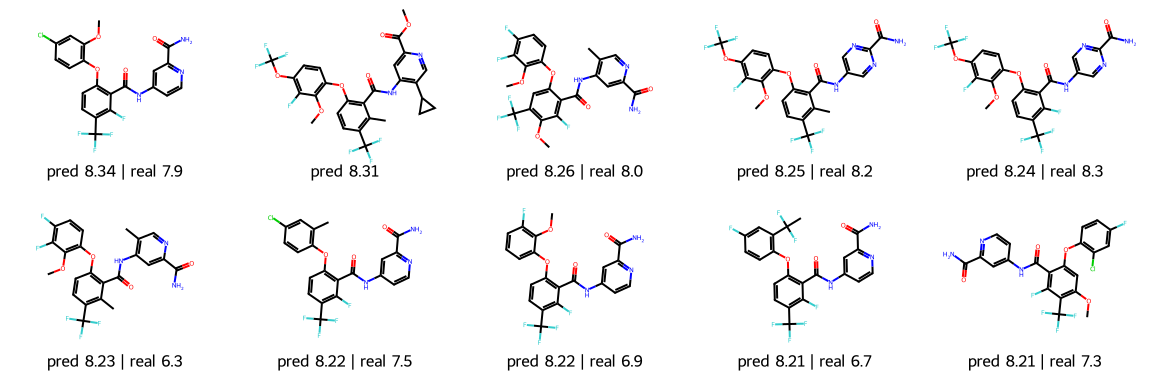

In [18]:
# Las estructuras: así se ve lo que el modelo propone
dibujar(recomendar(EJEMPLOS[0], k=10),
        f"Top-10 para {EJEMPLOS[0]} — {str(nom_tgt.get(EJEMPLOS[0], ''))[:58]}")

**Lectura.** La comparación justa de cada recomendación es contra la prevalencia **de esa proteína**, no contra 0.5: en una proteína donde el 80 % de los candidatos ya son activos queda poco margen, y en una donde son el 55 % el margen es amplio. Por eso cada ejemplo imprime su propio azar al lado.

En las estructuras se ve de inmediato lo que el modelo está haciendo: propone moléculas de la misma serie química que las que esa proteína ya tenía medidas. Es exactamente el principio de similitud en acción, y también su límite —el modelo explota lo conocido, no explora.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">11. Conclusiones</span></div>

In [19]:
H = {
    "Universo": f"{len(I):,} pares | {n_prot:,} proteínas | {n_lig:,} ligandos",
    "Densidad de la matriz": f"{100*len(I)/(n_prot*n_lig):.5f}%",
    "Moléculas medidas contra una sola proteína": f"{pct((prot_por_lig==1).sum(), len(prot_por_lig)):.1f}%",
    "Representación": f"ECFP{2*FP_RADIO} de {FP_BITS} bits | {K_MER}-meros",
    "Vecina por secuencia de la misma familia": f"{TASA_FAM:.1f}%",
    "Partición": f"temporal, train hasta {CORTE:.0f}",
    "Test con molécula nueva": f"{100*te['frio'].mean():.1f}%",
    "Pesos ajustados en validación": f"λ = {LAM:g} | γ = {GAM:g}",
    "Proteínas evaluadas": f"{det['target_id'].nunique():,}",
    "Azar (prevalencia)": f"{PREV_TE:.3f}",
    "Techo del enriquecimiento": f"{TECHO:.3f}×",
    "MODELO HÍBRIDO": "",
    f"  precision@{TOP_K}": f"{tabla.loc['híbrido', f'precision@{TOP_K}']:.4f}",
    f"  NDCG@{TOP_K}": f"{tabla.loc['híbrido', f'ndcg@{TOP_K}']:.4f}",
    "  enriquecimiento": f"{tabla.loc['híbrido','enriquecimiento']:.3f}× "
                         f"({tabla.loc['híbrido','% del margen']:.1f}% del margen)",
    "  AUC": f"{tabla.loc['híbrido','auc']:.4f}",
    "  RMSE": f"{tabla.loc['híbrido','rmse']:.3f}",
    "  r dentro de proteína": f"{dfc.loc['híbrido','r_dentro']:.3f}",
}
display(pd.Series(H, name="valor").to_frame())
RES["generado"] = pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")
RES["resumen"] = H
OUT_RES.write_text(json.dumps(RES, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
print(f"\nResultados en {OUT_RES}")

,valor
Universo,"1,248,252 pares | 3,444 proteínas | 830,999 li..."
Densidad de la matriz,0.04362%
Moléculas medidas contra una sola proteína,72.6%
Representación,ECFP4 de 2048 bits | 3-meros
Vecina por secuencia de la misma familia,52.2%
Partición,"temporal, train hasta 2022"
Test con molécula nueva,97.3%
Pesos ajustados en validación,λ = 2 | γ = 3
Proteínas evaluadas,668
Azar (prevalencia),0.632



Resultados en data\processed\rec_resultados.json


### Lo que queda demostrado

1. **La referencia no es 0.5 sino 0.62**, la prevalencia de activos, y el enriquecimiento tiene además un techo que depende de cuántos activos haya. `media_proteina` con AUC exactamente 0.500 certifica que la evaluación no infla nada.
2. **Las referencias simples no sirven.** Saber qué proteínas son fáciles o qué moléculas son potentes en general no basta: lo único que informa es la **interacción** entre una proteína concreta y una molécula concreta.
3. **El filtrado colaborativo clásico es inviable en esta matriz.** Cada molécula tiene 1.5 proteínas y el 72.6 % solo una, así que exigir que *esa misma* molécula la haya medido otra proteína no cubre ni un par con molécula nueva. Es un problema de estructura, no de implementación.
4. **La estructura química es lo que cruza el arranque en frío**, y funciona porque el principio de similitud se sostiene: el error baja monótonamente conforme sube el Tanimoto con la molécula parecida disponible.
5. **Las proteínas vecinas aportan señal real.** El óptimo de $\lambda$ está lejos de cero, y el vecindario por secuencia es lo que rescata a las proteínas con pocas mediciones.
6. **Partir al azar infla los resultados**, porque reparte análogos del mismo artículo entre entrenamiento y prueba. La partición temporal es la que reproduce el uso real.
7. **Una correlación mal reportada puede hacer pasar por bueno un modelo inútil.** Hay que calcularla dentro de cada proteína, y juzgarla contra el techo que impone el ruido experimental.

### Limitaciones

- **`activo` mide adherencia, no activación.** La variable es IC50; la actividad funcional (EC50) quedó fuera de la limpieza.
- **Solo se evalúa una parte de las proteínas**, las que tienen suficientes candidatos en prueba y ambas clases. A las de cola larga el modelo les recomienda, pero no se puede medir si acierta.
- **La representación de la proteína captura familia, no bolsillo**, y la partición temporal no controla homología: si en entrenamiento hay un homólogo casi idéntico, parte del acierto es transferencia de familia.
- **El sesgo de publicación está dentro de los datos.** El modelo aprende el espacio químico que la industria exploró, no el total.
- **El modelo explota, no explora.** Recomienda moléculas parecidas a las ya conocidas, que es lo que el principio de similitud permite; proponer química genuinamente nueva exigiría otro enfoque.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:18px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Referencias</span></div>

1. **BindingDB.** Liu, T., Lin, Y., Wen, X., Jorissen, R. N. y Gilson, M. K. (2007). BindingDB: a web-accessible database of experimentally determined protein–ligand binding affinities. *Nucleic Acids Research*, 35, D198–D201. — Volcado `BindingDB_All`, *release* 202611.
2. **Huellas circulares.** Rogers, D. y Hahn, M. (2010). Extended-Connectivity Fingerprints. *Journal of Chemical Information and Modeling*, 50(5), 742–754.
3. **Principio de similitud.** Johnson, M. A. y Maggiora, G. M. (1990). *Concepts and Applications of Molecular Similarity*. Wiley.
4. **Recomendación híbrida.** Burke, R. (2002). Hybrid Recommender Systems: Survey and Experiments. *User Modeling and User-Adapted Interaction*, 12(4), 331–370.
5. **Evaluación por ranking.** Järvelin, K. y Kekäläinen, J. (2002). Cumulated gain-based evaluation of IR techniques. *ACM Transactions on Information Systems*, 20(4), 422–446.
6. **RDKit.** Landrum, G. *RDKit: Open-source cheminformatics.* https://www.rdkit.org